<a href="https://colab.research.google.com/github/pranusha751/ITA0601-machine-learning/blob/main/EX_4(ML).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET: IRIS
Number of samples: 150
Number of features: 4
Flower classes: ['setosa' 'versicolor' 'virginica']

FIRST 5 DATA SAMPLES:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

ANN MODEL TRAINED SUCCESSFULLY

TEST ACCURACY: 96.67 %

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

CONFUSION MATRIX:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

NEW FLOWER MEASUREMENTS: [5.1 3.5 1.4 0.2]
PREDICTED FLOWER SPECIES: setosa


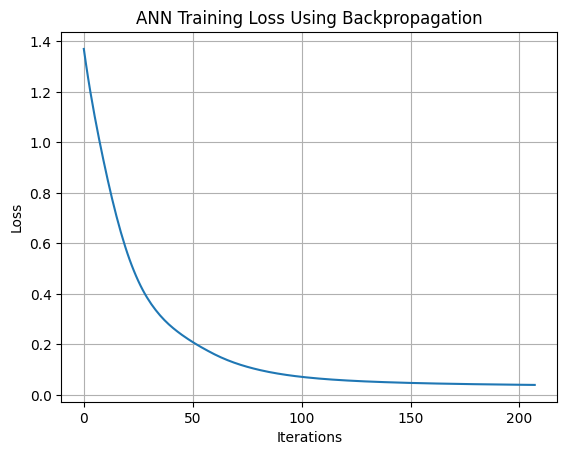

In [2]:

# Artificial Neural Network using Backpropagation
# Dataset: Iris

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

print("DATASET: IRIS")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower classes:", iris.target_names)

print("\nFIRST 5 DATA SAMPLES:")
print(X[:5])

# Step 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 3: Normalize the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Create the ANN model
# Hidden layer contains 10 neurons.
# 'adam' optimizer uses gradient-based learning.
# Backpropagation computes gradients to update weights.
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)

# Step 5: Train the model
model.fit(X_train, y_train)

print("\nANN MODEL TRAINED SUCCESSFULLY")

# Step 6: Test the model
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("\nTEST ACCURACY:", round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test, y_pred, target_names=iris.target_names
))

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

# Step 7: Predict a new flower sample
# Measurements: sepal length, sepal width,
# petal length, petal width (in cm)
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)[0]

print("\nNEW FLOWER MEASUREMENTS:", new_flower[0])
print("PREDICTED FLOWER SPECIES:", iris.target_names[prediction])

# Step 8: Plot the training loss
plt.plot(model.loss_curve_)
plt.title("ANN Training Loss Using Backpropagation")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()
